In [2]:
import glob, pickle, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['pdf.fonttype'] = 42

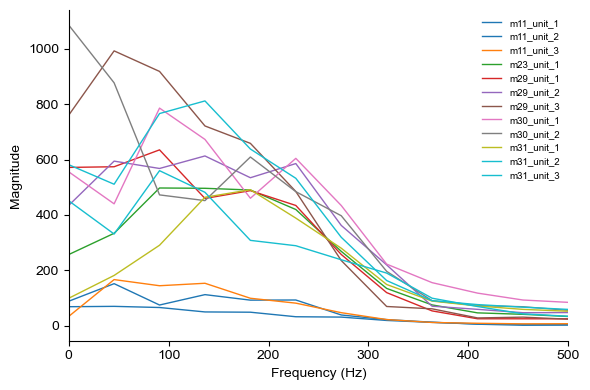

In [2]:
Fs = 3e4
in_path = '/Users/meghnaanand/Desktop/PiliferAnalysis/dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/'
files = sorted(glob.glob(in_path + '*.pickle'))
assert files, f'no pickles found in {in_path}'

fig, ax = plt.subplots(figsize=(6, 4))
colors = plt.cm.tab10(np.linspace(0, 1, len(files)))

for fp, c in zip(files, colors):
    ID = "_".join(os.path.basename(fp).split('_')[0:3])
    with open(fp, 'rb') as f:
        sta = np.asarray(pickle.load(f)[1]).ravel()   # index 1 = STA

    n     = len(sta)
    fft   = np.fft.rfft(sta)
    freqs = np.fft.rfftfreq(n, d=1/Fs)
    ax.plot(freqs, np.abs(fft), color=c, linewidth=1, label=ID)

ax.set_xlabel('Frequency (Hz)', fontsize=10)
ax.set_ylabel('Magnitude', fontsize=10)
ax.set_xlim(0, 500)
ax.legend(fontsize=7, frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig_out = '/Users/meghnaanand/Desktop/PiliferAnalysis/dataFolder/Figures/6d_STA_FFT/'
os.makedirs(fig_out, exist_ok=True)
plt.tight_layout()
fig.savefig(fig_out + 'STA_FFT_overlay.pdf', bbox_inches='tight')
plt.show()

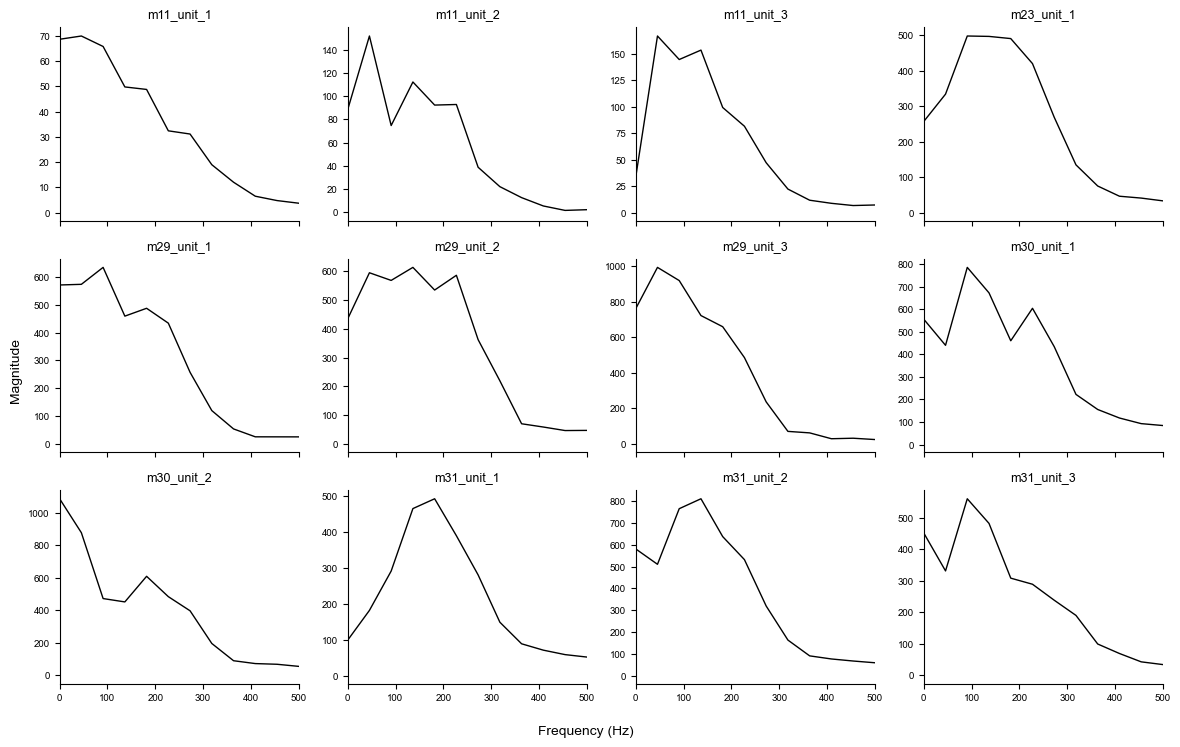

In [3]:
Fs = 3e4
in_path = '/Users/meghnaanand/Desktop/PiliferAnalysis/dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/'
files = sorted(glob.glob(in_path + '*.pickle'))
assert files, f'no pickles found in {in_path}'

n_files = len(files)
n_cols = 4
n_rows = int(np.ceil(n_files / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 2.5*n_rows), sharex=True)
axes = axes.flatten()

for i, fp in enumerate(files):
    ID = "_".join(os.path.basename(fp).split('_')[0:3])
    with open(fp, 'rb') as f:
        sta = np.asarray(pickle.load(f)[1]).ravel()   # index 1 = STA
    n     = len(sta)
    fft   = np.fft.rfft(sta)
    freqs = np.fft.rfftfreq(n, d=1/Fs)

    ax = axes[i]
    ax.plot(freqs, np.abs(fft), color='black', linewidth=1)
    ax.set_title(ID, fontsize=9)
    ax.set_xlim(0, 500)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=7)

# turn off any unused subplot axes (if n_files doesn't fill the grid evenly)
for j in range(i+1, len(axes)):
    axes[j].axis('off')

fig.supxlabel('Frequency (Hz)', fontsize=10)
fig.supylabel('Magnitude', fontsize=10)

fig_out = '/Users/meghnaanand/Desktop/PiliferAnalysis/dataFolder/Figures/6d_STA_FFT/'
os.makedirs(fig_out, exist_ok=True)
plt.tight_layout()
#fig.savefig(fig_out + 'STA_FFT_individual.pdf', bbox_inches='tight')
plt.show()